# Train a residual character projection
Read `training_data.pt`; train on cached embeddings only. Save only **residual_projection.pt**, replacing it only when validation balanced accuracy strictly improves. Epoch 0 is eligible and remains best on a tie.

The checkpoint contains weights, model/training settings, selected epoch, validation metrics, raw/projected pair thresholds, and a dataset hash. No optimizer state, per-epoch checkpoints, or log files are saved.


## 1. Settings and loaders
Training reads triplets. Validation reads the original SAME/DIFFERENT pairs. Test data never selects a checkpoint or threshold. Use Godfather with CUDA for the full experiment.


In [1]:
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import hashlib
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path('C:/Users/ESHAAN/BYTE/Applied-Task/Magi/charSimResidual')
DATA_FILE = ROOT / 'training_data.pt'
MODEL_FILE = ROOT / 'residual_projection.pt'
SEED, BATCH_SIZE, EPOCHS, PATIENCE = 42, 256, 50, 30
LEARNING_RATE, WEIGHT_DECAY, MARGIN = 1e-4, 1e-4, 0.2
MODEL_CONFIG = dict(embedding_dim=768, hidden_dim=64)
assert torch.cuda.is_available(), 'Use Godfather with CUDA-enabled PyTorch.'
device = torch.device('cuda:0')
torch.manual_seed(SEED)
data = torch.load(DATA_FILE, map_location='cpu', weights_only=True)
assert data['version'] == 3
with DATA_FILE.open('rb') as file:
    data_hash = hashlib.file_digest(file, 'sha256').hexdigest()
assert not (set(data['splits']['train']) & set(data['splits']['validation']) or
            set(data['splits']['train']) & set(data['splits']['test']) or
            set(data['splits']['validation']) & set(data['splits']['test']))
print('GPU:', torch.cuda.get_device_name(device))

class TripletDataset(Dataset):
    def __init__(self):
        self.rows = data['triplets']['indices']
        assert len(self.rows), 'No training triplets.'

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        i, a, p, n = self.rows[index].tolist()
        embeddings = data['sequences'][i]['embeddings']
        return embeddings[a], embeddings[p], embeddings[n]

class PairDataset(Dataset):
    def __init__(self):
        self.rows = data['pairs']['validation']
        assert len(self.rows) and set(self.rows[:, 3].tolist()) == {0, 1}

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        i, a, b, label = self.rows[index].tolist()
        embeddings = data['sequences'][i]['embeddings']
        return embeddings[a], embeddings[b], label

loaders = dict(
    train=DataLoader(TripletDataset(), batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True),
    validation=DataLoader(PairDataset(), batch_size=BATCH_SIZE, num_workers=0, pin_memory=True))
print('Training triplets:', len(loaders['train'].dataset))
print('Validation pairs:', len(loaders['validation'].dataset))


GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Training triplets: 531
Validation pairs: 693


## 2. Residual model and cosine triplet loss
Normalize input, add the learned correction, then normalize output. The zero final layer preserves normalized raw Magi at epoch 0 within floating-point precision.

Loss is `max(0, negative_similarity - positive_similarity + 0.2)`. The margin is a ranking target, not a classification threshold.


In [3]:
class ResidualCharacterProjection(nn.Module):
    def __init__(self, embedding_dim=768, hidden_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(embedding_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, embedding_dim)
        nn.init.zeros_(self.fc2.weight)
        nn.init.zeros_(self.fc2.bias)

    def forward(self, x):
        x = F.normalize(x, dim=-1)
        delta = self.fc2(F.relu(self.fc1(x)))
        return F.normalize(x + delta, dim=-1)

def cosine_triplet_loss(anchor, positive, negative, margin=0.2):
    positive_similarity = (anchor * positive).sum(dim=-1)
    negative_similarity = (anchor * negative).sum(dim=-1)
    return (negative_similarity - positive_similarity + margin).clamp(min=0).mean()

model = ResidualCharacterProjection(**MODEL_CONFIG).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)


## 3. Validation metrics and thresholds
Search observed validation score boundaries rather than a coarse fixed grid. Select thresholds on validation only. Class recalls and cross-page metrics reveal problems hidden by overall loss.


In [4]:
def metrics(scores, labels, threshold):
    predicted = scores >= threshold
    positive, negative = labels == 1, labels == 0
    same = float(predicted[positive].mean()) if positive.any() else float('nan')
    different = float((~predicted[negative]).mean()) if negative.any() else float('nan')
    return dict(balanced_accuracy=(same + different) / 2,
                same_recall=same, different_recall=different,
                accuracy=float((predicted == labels).mean()) if len(labels) else float('nan'))

def choose_threshold(scores, labels):
    # Check all distinct score boundaries efficiently, including predicting nobody SAME.
    assert set(labels.tolist()) == {0, 1}
    order = np.argsort(-scores, kind='stable')
    values, targets = scores[order], labels[order]
    ends = np.r_[np.where(values[:-1] != values[1:])[0], len(values)-1]
    tp = np.cumsum(targets)[ends]
    fp = (ends + 1) - tp
    balanced = (tp / targets.sum() + 1 - fp / (len(targets)-targets.sum())) / 2
    best = int(np.argmax(balanced))
    return float(values[ends[best]]) if balanced[best] > 0.5 else float(np.nextafter(float(values[0]), np.inf))

@torch.inference_mode()
def validation_scores(check_identity=False):
    model.eval()
    raw, projected, labels = [], [], []
    for a, b, y in loaders['validation']:
        a, b = a.to(device), b.to(device)
        raw_a, raw_b = F.normalize(a, dim=-1), F.normalize(b, dim=-1)
        za, zb = model(a), model(b)
        if check_identity:
            torch.testing.assert_close(za, raw_a, rtol=1e-5, atol=1e-6)
            torch.testing.assert_close(zb, raw_b, rtol=1e-5, atol=1e-6)
        raw.append((raw_a * raw_b).sum(dim=-1).clamp(-1, 1).cpu().numpy())
        projected.append((za * zb).sum(dim=-1).clamp(-1, 1).cpu().numpy())
        labels.append(y.numpy())
    rows = data['pairs']['validation']
    cross = np.array([int(data['sequences'][i]['page'][a]) != int(data['sequences'][i]['page'][b])
                      for i, a, b, _ in rows.tolist()])
    return np.concatenate(raw), np.concatenate(projected), np.concatenate(labels), cross

def train_epoch():
    model.train()
    total_loss = 0.0
    for anchor, positive, negative in loaders['train']:
        anchor, positive, negative = [x.to(device, non_blocking=True)
                                      for x in (anchor, positive, negative)]
        optimizer.zero_grad()
        loss = cosine_triplet_loss(model(anchor), model(positive), model(negative), MARGIN)
        assert torch.isfinite(loss), 'Non-finite training loss.'
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(anchor)
    return total_loss / len(loaders['train'].dataset)

@torch.inference_mode()
def check_epoch_zero():
    model.eval()
    # Check every cached appearance, including unaccepted appearances used by clustering.
    for sequence in data['sequences']:
        for batch in sequence['embeddings'].split(BATCH_SIZE):
            batch = batch.to(device)
            torch.testing.assert_close(model(batch), F.normalize(batch, dim=-1),
                                       rtol=1e-5, atol=1e-6)
    raw, projected, labels, cross = validation_scores(check_identity=True)
    np.testing.assert_allclose(projected, raw, rtol=1e-5, atol=1e-6)
    print('Epoch 0 sanity check passed: normalized embeddings and validation scores match raw Magi.')
    return raw, projected, labels, cross


## 4. Evaluate epoch 0, then train
Stop immediately if epoch-0 embeddings or scores differ from normalized raw Magi beyond floating-point tolerance. Save epoch 0 first. Only a strictly higher validation balanced accuracy replaces it; loss never breaks a tie.

Stop after `PATIENCE` epochs without improvement. Training loss and validation balanced accuracy are displayed in the notebook only.


Epoch 0 sanity check passed: normalized embeddings and validation scores match raw Magi.
00 | validation BA=0.7260 | checkpoint saved
01 | triplet loss=0.1333 | validation BA=0.7260 | cross BA=0.7467
02 | triplet loss=0.1330 | validation BA=0.7260 | cross BA=0.7467
03 | triplet loss=0.1328 | validation BA=0.7260 | cross BA=0.7467
04 | triplet loss=0.1324 | validation BA=0.7260 | cross BA=0.7467
05 | triplet loss=0.1321 | validation BA=0.7260 | cross BA=0.7467
06 | triplet loss=0.1317 | validation BA=0.7250 | cross BA=0.7482
07 | triplet loss=0.1314 | validation BA=0.7260 | cross BA=0.7453
08 | triplet loss=0.1309 | validation BA=0.7260 | cross BA=0.7453
09 | triplet loss=0.1305 | validation BA=0.7271 | cross BA=0.7453
10 | triplet loss=0.1300 | validation BA=0.7271 | cross BA=0.7453
11 | triplet loss=0.1295 | validation BA=0.7250 | cross BA=0.7410
12 | triplet loss=0.1291 | validation BA=0.7250 | cross BA=0.7453
13 | triplet loss=0.1286 | validation BA=0.7239 | cross BA=0.7410
14 | tri

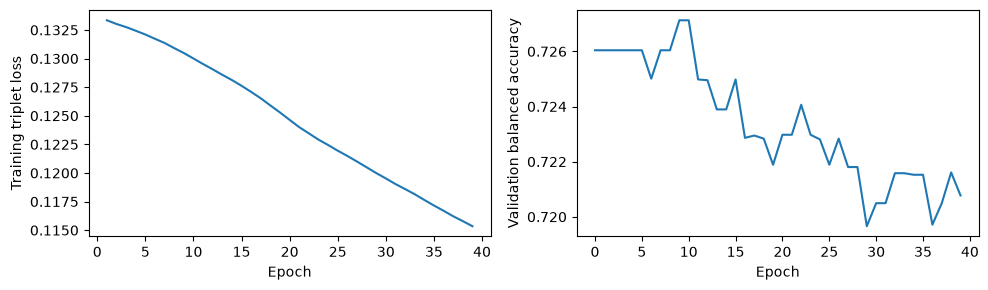

Best epoch: 9 | validation metrics: {'balanced_accuracy': 0.7271272625489831, 'same_recall': 0.6738197424892703, 'different_recall': 0.7804347826086957, 'accuracy': 0.7445887445887446}
Saved one checkpoint: C:\Users\ESHAAN\BYTE\Applied-Task\Magi\charSimResidual\residual_projection.pt


In [5]:
raw, projected, labels, cross = check_epoch_zero()
raw_threshold = choose_threshold(raw, labels)

# Calibrate each score array separately so normalization roundoff at a boundary is harmless.
threshold = choose_threshold(projected, labels)
baseline_result = metrics(raw, labels, raw_threshold)
epoch_zero_result = metrics(projected, labels, threshold)
assert epoch_zero_result == baseline_result, 'Epoch 0 decisions differ from raw Magi; fix before training.'
best_accuracy = baseline_result['balanced_accuracy']
bad_epochs = 0
history = []

def save_checkpoint(epoch, result, threshold):
    checkpoint = dict(version=3,
                      model_state={k: v.detach().cpu() for k, v in model.state_dict().items()},
                      model_config=MODEL_CONFIG,
                      training=dict(seed=SEED, margin=MARGIN, learning_rate=LEARNING_RATE,
                                    weight_decay=WEIGHT_DECAY, batch_size=BATCH_SIZE,
                                    max_epochs=EPOCHS, patience=PATIENCE),
                      epoch=epoch, validation_metrics=result,
                      epoch_zero_validation_metrics=baseline_result,
                      threshold=threshold, raw_threshold=raw_threshold, data_hash=data_hash)
    torch.save(checkpoint, MODEL_FILE)

save_checkpoint(0, epoch_zero_result, threshold)
print(f"00 | validation BA={best_accuracy:.4f} | checkpoint saved")
for epoch in range(1, EPOCHS + 1):
    train_loss = train_epoch()
    _, projected, labels, cross = validation_scores()
    threshold = choose_threshold(projected, labels)
    result = metrics(projected, labels, threshold)
    cross_result = metrics(projected[cross], labels[cross], threshold)
    accuracy = result['balanced_accuracy']
    assert np.isfinite(train_loss) and np.isfinite(accuracy)
    history.append((epoch, train_loss, accuracy))
    print(f"{epoch:02d} | triplet loss={train_loss:.4f} | validation BA={accuracy:.4f} | cross BA={cross_result['balanced_accuracy']:.4f}")
    if accuracy > best_accuracy:
        best_accuracy, bad_epochs = accuracy, 0
        save_checkpoint(epoch, result, threshold)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print('Early stopping.')
            break

saved = torch.load(MODEL_FILE, map_location='cpu', weights_only=True)
model.load_state_dict(saved['model_state'])
model.eval()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot([h[0] for h in history], [h[1] for h in history])
axes[0].set(xlabel='Epoch', ylabel='Training triplet loss')
axes[1].plot([0] + [h[0] for h in history],
             [baseline_result['balanced_accuracy']] + [h[2] for h in history])
axes[1].set(xlabel='Epoch', ylabel='Validation balanced accuracy')
plt.tight_layout(); plt.show()
print('Best epoch:', saved['epoch'], '| validation metrics:', saved['validation_metrics'])
print('Saved one checkpoint:', MODEL_FILE)
